# RBM Implementation
## Imports

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

from matplotlib import pyplot as plt
from tqdm import tqdm

# Force FP32 computation for GPU-based training (train_rbm_parallel)
policy = tf.keras.mixed_precision.Policy('float32')
tf.keras.mixed_precision.set_global_policy(policy)

I0000 00:00:1793629449.256831  116799 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793629449.283924  116799 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793629450.029067  116799 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## RBM Class and supporting functions
RBM class for single-layer RBM implementation, and other supporting functions to train the model, extract features, save and load weights

In [2]:
import sys
import os
sys.path.append(os.path.abspath('..'))

from src import RBM, train_rbm, train_rbm_parallel, extract_features, save_rbm 

INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0',)


I0000 00:00:1793629451.046758  116799 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2883 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


## RBM application on preprocessed data
See `01_data_eda.ipynb` for data preprocessed into tensors.

In [3]:
VOCAB_SIZE = 1001

X_raw = np.load('../data/processed/X_raw.npy')
#y_target = np.load('../data/processed/y_target.npy')

print(f"X_raw shape: {X_raw.shape}")

X_raw shape: (95072, 1001)


In [4]:
# Training Variables
HIDDEN_UNITS = 500
VOCAB_SIZE = 1001
EPOCHS = 50
LEARNING_RATE = 0.0001
BATCH_SIZE = 256

  0%|                                                               | 0/50 [00:00<?, ?it/s]I0000 00:00:1793629451.575088  116799 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
/home/parth/Projects/BITS/DM/next-basket-prediction/.venv/lib/python3.14/site-packages/keras/src/optimizers/base_optimizer.py:865: UserWarning: Gradients do not exist for variables ['rbm/weights', 'rbm/hidden_bias', 'rbm/visible_bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(
100%|██████████████████████████████████████████████████████| 50/50 [00:35<00:00,  1.42it/s]


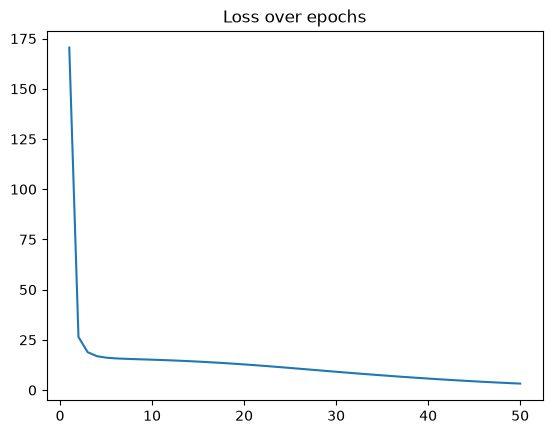

In [5]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    rbm = train_rbm_parallel(
        visible_units=VOCAB_SIZE,
        hidden_units=HIDDEN_UNITS,
        learning_rate=LEARNING_RATE,
        k=1,
        data=X_raw.reshape(-1, VOCAB_SIZE),
        epochs=EPOCHS, batch_size=BATCH_SIZE
    )
else:
    rbm = train_rbm(
        visible_units=VOCAB_SIZE,
        hidden_units=HIDDEN_UNITS,
        learning_rate=LEARNING_RATE,
        k=1,  epochs=EPOCHS, batch_size=BATCH_SIZE,
        data=X_raw.reshape(-1, VOCAB_SIZE)
    )

In [6]:
features = extract_features(rbm, X_raw.reshape(-1, VOCAB_SIZE))

save_rbm(rbm, '../data/rbm/rbm.weights.h5')